In [1]:
import os
import shutil
import subprocess
import sys
from pathlib import Path

from google.colab import drive

drive.mount("/content/drive")

REPO_URL = "https://github.com/javiannnnn/wafer-triage-project.git"  # e.g. "https://github.com/<you>/<repo>.git"
assert REPO_URL, "Set REPO_URL to the GitHub URL of this project"

DRIVE_DIR = Path("/content/drive/MyDrive/wm811k")
WORK_DIR = Path("/content/work")
FILES = ["experiment_data.npz", "mlflow.db", "simclr_encoder.pt", "simclr_encoder.pt.fingerprint"]


def restore_progress():
    """Copy anything saved by an earlier session from Drive to the local work dir."""
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    for name in FILES:
        if (DRIVE_DIR / name).exists() and not (WORK_DIR / name).exists():
            shutil.copy2(DRIVE_DIR / name, WORK_DIR / name)
    if (DRIVE_DIR / "mlartifacts").exists():
        shutil.copytree(DRIVE_DIR / "mlartifacts", WORK_DIR / "mlartifacts", dirs_exist_ok=True)


def save_progress():
    """Copy the MLflow database, logged models and SimCLR checkpoint to Drive."""
    for name in FILES[1:]:
        if (WORK_DIR / name).exists():
            shutil.copy2(WORK_DIR / name, DRIVE_DIR / name)
    if (WORK_DIR / "mlartifacts").exists():
        shutil.copytree(WORK_DIR / "mlartifacts", DRIVE_DIR / "mlartifacts", dirs_exist_ok=True)

Mounted at /content/drive


In [2]:
!git clone -q $REPO_URL /content/wm811k
!pip install -q hydra-core mlflow xgboost scikit-learn pandas matplotlib
restore_progress()
print(sorted(p.name for p in WORK_DIR.iterdir()))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
['experiment_data.npz', 'mlartifacts', 'mlflow.db', 'simclr_encoder.pt', 'simclr_encoder.pt.fingerprint']


In [3]:
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
sys.path.insert(0, "/content/wm811k/src")

OVERRIDES = [
    f"data.cache={WORK_DIR}/experiment_data.npz",
    f"mlflow.tracking_uri=sqlite:///{WORK_DIR}/mlflow.db",
    f"mlflow.artifact_root={WORK_DIR}/mlartifacts",
    f"simclr.checkpoint={WORK_DIR}/simclr_encoder.pt",
    f"artifacts_dir={WORK_DIR}/artifacts",
    f"export_dir={WORK_DIR}/models/best_model",
    "train.num_workers=4",
]

from wm811k.config import load_config
from wm811k.pipeline import prepare_experiment_data
from wm811k.sweep import run_sweep

cfg = load_config(OVERRIDES)
data = prepare_experiment_data(cfg)


def sweep_arm(name):
    """Run one arm, saving progress to Drive after every run and again if one fails."""
    try:
        run_sweep(cfg, data, [name], after_run=save_progress)
    finally:
        save_progress()


def wm811k(command, *args):
    """Run `python -m wm811k.cli <command>` with the same overrides and stream its output."""
    env = {**os.environ, "PYTHONPATH": "/content/wm811k/src"}
    subprocess.run(
        ["python", "-m", "wm811k.cli", command, *args, *OVERRIDES],
        cwd="/content/wm811k", env=env, check=True,
    )

## Sweep
One arm per cell. 15 runs per arm (5 budgets x 3 seeds). SimCLR pretrains once first.

In [4]:
sweep_arm('gbm')

In [5]:
sweep_arm('cnn')

In [6]:
sweep_arm('simclr')

In [7]:
sweep_arm('fixmatch')

2026/11/03 06:57:26 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/11/03 06:57:26 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/03 06:57:36 WARNING mlflow.utils.requirements_utils: Found torchvision version (0.26.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torchvision==0.26.0' without the loca

## Results

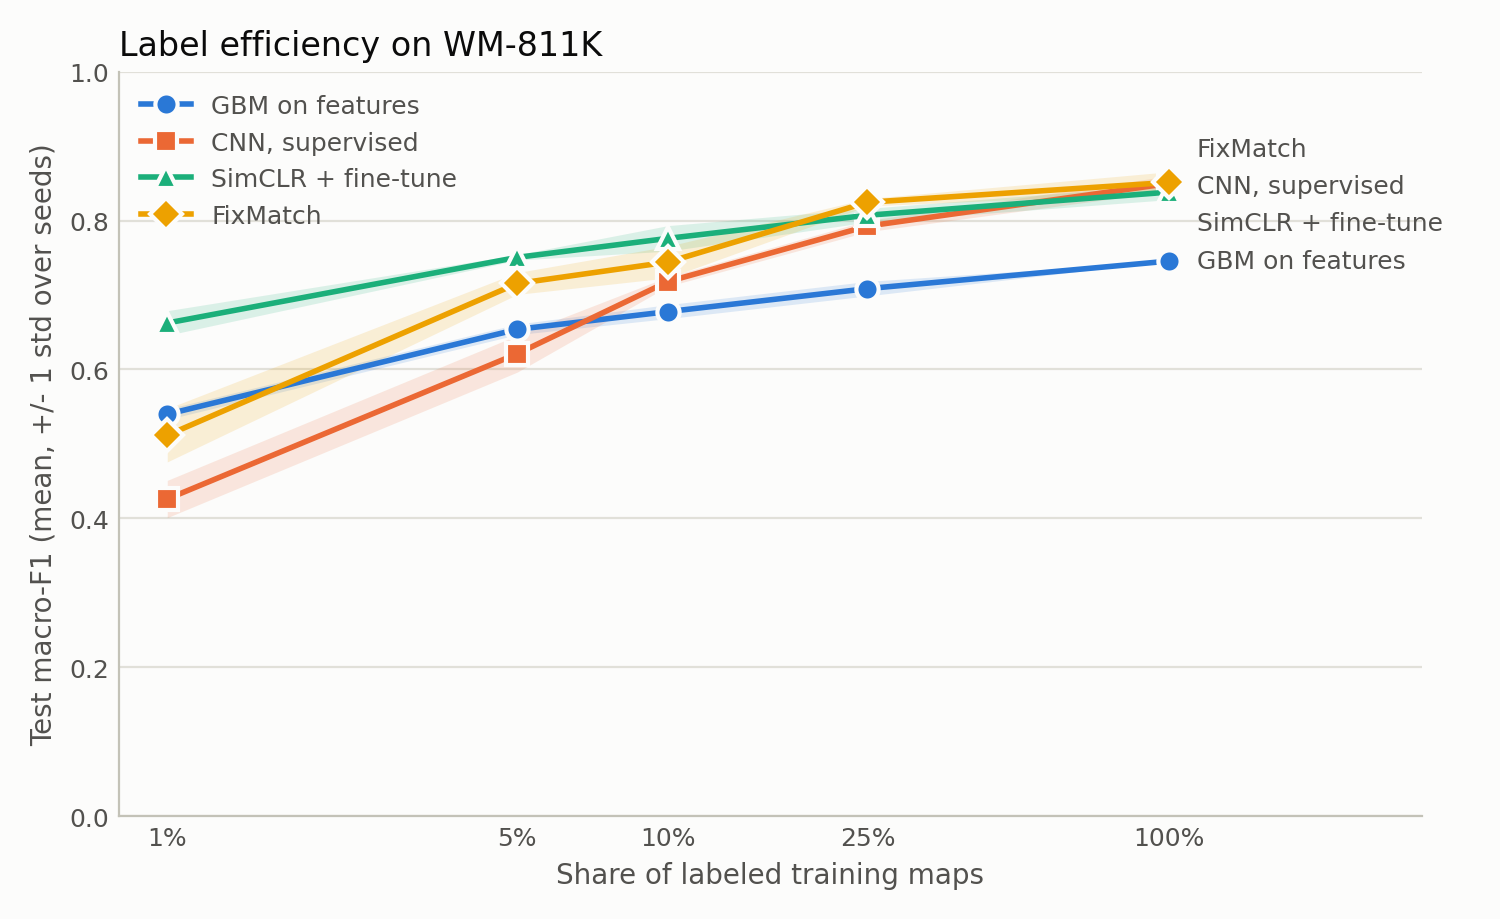

In [8]:
wm811k("results")
shutil.copytree(WORK_DIR / "artifacts", DRIVE_DIR / "artifacts", dirs_exist_ok=True)
from IPython.display import Image

Image(str(WORK_DIR / "artifacts" / "label_efficiency.png"))

## Export the best model

`export` picks the best full-label run by validation macro-F1, registers it, and writes the weights plus a held-out gate sample. It prints a sample macro-F1: use that to set `gate.min_macro_f1`. `reference` then builds the drift reference.

In [9]:
wm811k('export')
wm811k('reference')
shutil.copytree(WORK_DIR / "models" / "best_model", DRIVE_DIR / "models" / "best_model", dirs_exist_ok=True)

PosixPath('/content/drive/MyDrive/wm811k/models/best_model')

Download `models/best_model/` and `artifacts/` from Drive into the repo root, set `gate.min_macro_f1` in `conf/config.yaml` just under the printed sample macro-F1, and commit `models/best_model/`. CI then re-scores the committed weights on the committed sample, and the Docker job builds the image.